# Visualizing Power System Stability Dynamics

This notebook demonstrates scientific visualization techniques for analyzing power system stability using event simulation data from the TranPy datasets.

## Overview

We analyze time-series data from transient stability simulations of two power systems:
- **New England 39-Bus System**
- **IEEE 9-Bus System**

Each event represents a 10-second simulation at 1ms resolution, capturing voltage, frequency, phase angle, and power measurements across all buses and generators.

**Stability Criterion**: A system is classified as **unstable** if any connected generator experiences an out-of-step condition (`outofstep = 1`).

## 1. Setup and Imports

In [209]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configure publication-quality plots
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
sns.set_style('whitegrid')
sns.set_palette('colorblind')

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 2. Data Loading and Preprocessing

In [210]:
def load_event_data(system='NineBusSystem', event_id=0):
    """
    Load event simulation data from CSV files.
    
    Parameters
    ----------
    system : str
        Either 'NewEngland' or 'NineBusSystem'
    event_id : int
        Event identifier (0-9999)
    
    Returns
    -------
    df : pd.DataFrame
        Time-series data with parsed columns
    is_stable : bool
        Stability classification (False = unstable)
    """
    # Construct file path
    base_path = Path('..') / 'src' / 'tranpy' / 'data' / 'datasets' / 'events'
    file_path = base_path / system / f'results_event_{event_id}.csv'
    
    if not file_path.exists():
        raise FileNotFoundError(f"Event file not found: {file_path}")
    
    # Read the two header rows
    header_row1 = pd.read_csv(file_path, nrows=0).columns.tolist()  # Element names
    header_row2 = pd.read_csv(file_path, skiprows=1, nrows=0).columns.tolist()  # Variable names
    
    # Combine headers to create unique column names (for internal use)
    combined_headers = []
    for elem, var in zip(header_row1, header_row2):
        combined_headers.append(f"{elem}|{var}")
    
    # Load data with combined headers
    df = pd.read_csv(file_path, skiprows=2, names=combined_headers)
    
    # Rename time column
    df.rename(columns={df.columns[0]: 'time'}, inplace=True)
    
    # Determine stability from outofstep columns
    outofstep_cols = [col for col in df.columns if 'outofstep' in col.lower()]
    if outofstep_cols:
        is_stable = df[outofstep_cols].max().max() == 0
    else:
        is_stable = True  # If no outofstep column, assume stable
    
    return df, is_stable

def extract_bus_measurements(df, variable='m:u'):
    """
    Extract bus measurements for a specific variable.
    
    Parameters
    ----------
    df : pd.DataFrame
        Event data
    variable : str
        Variable name (e.g., 'm:u' for voltage, 'm:fehz' for frequency)
    
    Returns
    -------
    bus_data : pd.DataFrame
        Time-series for each bus with clean column names
    """
    import re
    
    # Find columns with the variable and containing 'Bus' in the element name
    var_cols = []
    col_mapping = {}
    
    for col in df.columns:
        if col == 'time':
            continue
        if variable in col and 'Bus' in col:
            var_cols.append(col)
            
            # Extract bus number from element name
            element = col.split('|')[0]
            match = re.search(r'Bus[\\s]+(\d+)', element)
            if match:
                bus_num = match.group(1).lstrip('0')  # Remove leading zeros
                if not bus_num:  # If all zeros
                    bus_num = '0'
                col_mapping[col] = f'Bus {bus_num}'
            else:
                # Fallback: try to find any number after Bus
                match = re.search(r'Bus.*?(\d+)', element)
                if match:
                    bus_num = match.group(1).lstrip('0')
                    if not bus_num:
                        bus_num = '0'
                    col_mapping[col] = f'Bus {bus_num}'
    
    if not var_cols:
        print(f"Warning: No columns found for variable '{variable}' with Bus")
        return pd.DataFrame({'time': df['time']})
    
    bus_data = df[['time'] + var_cols].copy()
    bus_data.rename(columns=col_mapping, inplace=True)
    
    return bus_data

def extract_generator_measurements(df, variable='s:xspeed'):
    """
    Extract generator measurements for a specific variable.
    
    Parameters
    ----------
    df : pd.DataFrame
        Event data
    variable : str
        Variable name (e.g., 's:xspeed' for rotor speed, 's:P1' for active power)
    
    Returns
    -------
    gen_data : pd.DataFrame
        Time-series for each generator with clean column names
    """
    import re
    
    # Find columns with the variable and containing 'G' (generator) in the element name
    var_cols = []
    col_mapping = {}
    
    for col in df.columns:
        if col == 'time':
            continue
        # Look for generator indicators: \G or Grid\G
        if variable in col and ('\\G ' in col or '\\G' in col.split('|')[0]):
            var_cols.append(col)
            
            # Extract generator number from element name
            element = col.split('|')[0]
            match = re.search(r'\\G[\\s]+(\d+)', element)
            if match:
                gen_num = match.group(1).lstrip('0')  # Remove leading zeros
                if not gen_num:  # If all zeros
                    gen_num = '0'
                col_mapping[col] = f'Gen {gen_num}'
            else:
                # Fallback: try to find any number after G
                match = re.search(r'\\G.*?(\d+)', element)
                if match:
                    gen_num = match.group(1).lstrip('0')
                    if not gen_num:
                        gen_num = '0'
                    col_mapping[col] = f'Gen {gen_num}'
    
    if not var_cols:
        print(f"Warning: No columns found for variable '{variable}' with Generator")
        return pd.DataFrame({'time': df['time']})
    
    gen_data = df[['time'] + var_cols].copy()
    gen_data.rename(columns=col_mapping, inplace=True)
    
    return gen_data

print("✓ Data loading functions defined")

✓ Data loading functions defined


## Configure System and Load Example Events

**Select the power system to analyze:**
- `'NineBusSystem'` - IEEE 9-Bus System (9 buses, 3 generators)
- `'NewEngland'` - New England 39-Bus System (39 buses, 10 generators)

In [211]:
# ============================================================================
# CONFIGURATION: Select your power system here
# ============================================================================
system_name = 'NewEngland'  # Change to 'NewEngland' for 39-bus system
# ============================================================================

# System metadata
system_info = {
    'NineBusSystem': {'n_buses': 9, 'n_generators': 3, 'display_name': 'IEEE 9-bus'},
    'NewEngland': {'n_buses': 39, 'n_generators': 10, 'display_name': 'New England 39-bus'}
}
event_id = 3
n_events=3
    
# Load event 0
df_event, is_stable = load_event_data(system=system_name, event_id=event_id)

print("=" * 70)
print(f"System: {system_info[system_name]['display_name']}")
print(f"Number of Buses: {system_info[system_name]['n_buses']}")
print(f"Number of Generators: {system_info[system_name]['n_generators']}")
print("=" * 70)
print(f"Event 0 Stability: {'✓ Stable' if is_stable else '✗ Unstable'}")
print(f"Time span: {df_event['time'].min():.3f}s to {df_event['time'].max():.3f}s")
print(f"Time steps: {len(df_event)}")
print(f"Total columns: {len(df_event.columns)}")
print("=" * 70)

# Display first few rows
df_event.head()

System: New England 39-bus
Number of Buses: 39
Number of Generators: 10
Event 0 Stability: ✗ Unstable
Time span: -0.100s to 10.000s
Time steps: 344
Total columns: 322


,time,Grid\Bus 01.ElmTerm|m:u in p.u.,Grid\Bus 01.ElmTerm.1|m:phiu in deg,Grid\Bus 01.ElmTerm.2|m:fehz in Hz,Grid\Bus 02.ElmTerm|m:u in p.u..1,Grid\Bus 02.ElmTerm.1|m:phiu in deg.1,Grid\Bus 02.ElmTerm.2|m:fehz in Hz.1,Grid\Bus 03.ElmTerm|m:u in p.u..2,Grid\Bus 03.ElmTerm.1|m:phiu in deg.2,Grid\Bus 03.ElmTerm.2|m:fehz in Hz.2,...,Grid\Line 17 - 18.ElmLne|c:loading in %.24,Grid\Line 17 - 27.ElmLne|c:loading in %.25,Grid\Line 21 - 22.ElmLne|c:loading in %.26,Grid\Line 22 - 23.ElmLne|c:loading in %.27,Grid\Line 23 - 24.ElmLne|c:loading in %.28,Grid\Line 25 - 26.ElmLne|c:loading in %.29,Grid\Line 26 - 27.ElmLne|c:loading in %.30,Grid\Line 26 - 28.ElmLne|c:loading in %.31,Grid\Line 26 - 29.ElmLne|c:loading in %.32,Grid\Line 28 - 29.ElmLne|c:loading in %.33
0,-0.10,1.047366,-8.437053,50.0,1.048768,-5.759011,50.0,1.030224,-8.601016,50.0,...,34.314141,7.738051,99.050597,12.056842,56.70334,12.824997,44.410314,24.186227,32.5305,55.914775
1,-0.07,1.047366,-8.437053,50.0,1.048768,-5.759011,50.0,1.030224,-8.601016,50.0,...,34.314141,7.738051,99.050597,12.056842,56.70334,12.824997,44.410314,24.186227,32.5305,55.914775
2,-0.04,1.047366,-8.437053,50.0,1.048768,-5.759011,50.0,1.030224,-8.601016,50.0,...,34.314141,7.738051,99.050597,12.056842,56.70334,12.824997,44.410314,24.186227,32.5305,55.914775
3,-0.01,1.047366,-8.437053,50.0,1.048768,-5.759011,50.0,1.030224,-8.601016,50.0,...,34.314141,7.738051,99.050597,12.056842,56.70334,12.824997,44.410314,24.186227,32.5305,55.914775
4,0.00,1.047366,-8.437053,50.0,1.048768,-5.759011,50.0,1.030224,-8.601016,50.0,...,34.314141,7.738051,99.050597,12.056842,56.70334,12.824997,44.410314,24.186227,32.5305,55.914775


## 3. Voltage Magnitude Dynamics

Voltage magnitude is a critical indicator of system stability. During unstable events, voltages typically exhibit larger deviations and oscillations.

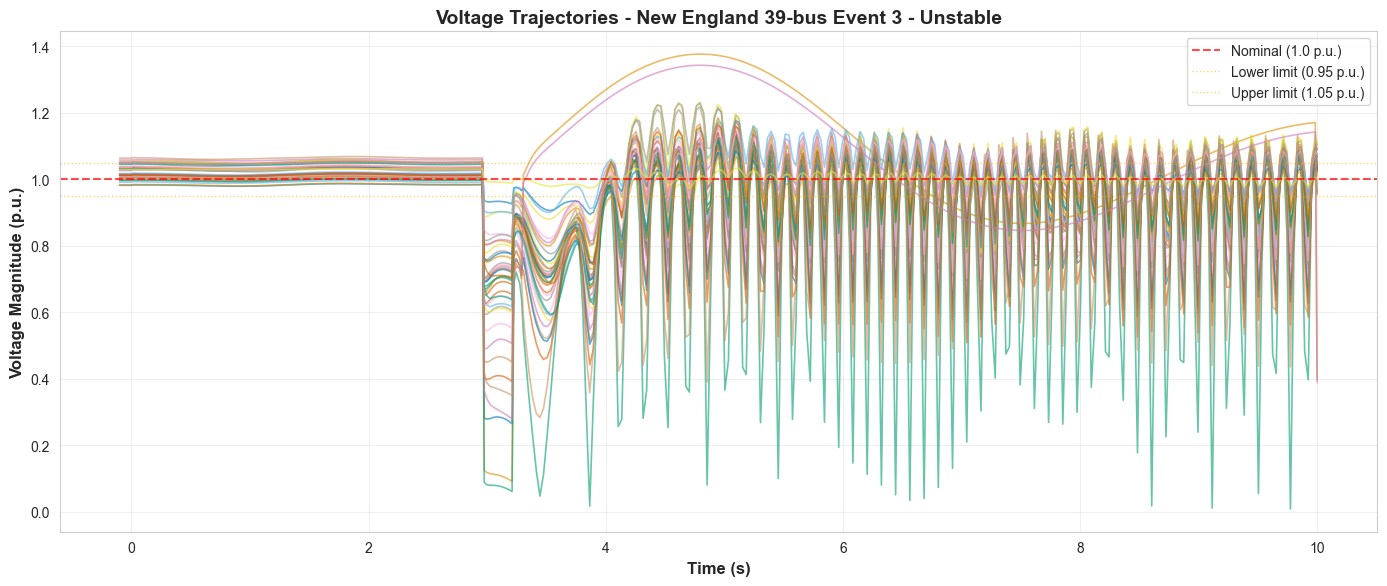

Number of buses plotted: 39
Voltage range: 0.009 - 1.376 p.u.


In [212]:
# Extract voltage data
voltage_data = extract_bus_measurements(df_event, variable='m:u')

# Plot voltage trajectories
fig, ax = plt.subplots(figsize=(14, 6))

# Plot each bus
for col in voltage_data.columns[1:]:  # Skip time column
    ax.plot(voltage_data['time'], voltage_data[col], alpha=0.6, linewidth=1.2)

ax.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Nominal (1.0 p.u.)')
ax.axhline(y=0.95, color='orange', linestyle=':', linewidth=1, alpha=0.5, label='Lower limit (0.95 p.u.)')
ax.axhline(y=1.05, color='orange', linestyle=':', linewidth=1, alpha=0.5, label='Upper limit (1.05 p.u.)')

ax.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
ax.set_ylabel('Voltage Magnitude (p.u.)', fontsize=12, fontweight='bold')
ax.set_title(f'Voltage Trajectories - {system_info[system_name]["display_name"]} Event {event_id} - {'Stable' if is_stable else 'Unstable'}', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

print(f"Number of buses plotted: {len(voltage_data.columns) - 1}")
print(f"Voltage range: {voltage_data.iloc[:, 1:].min().min():.3f} - {voltage_data.iloc[:, 1:].max().max():.3f} p.u.")

## 4. Frequency Deviation Analysis

System frequency should remain close to 50 Hz (or 60 Hz in some regions). Large deviations indicate loss of synchronism.

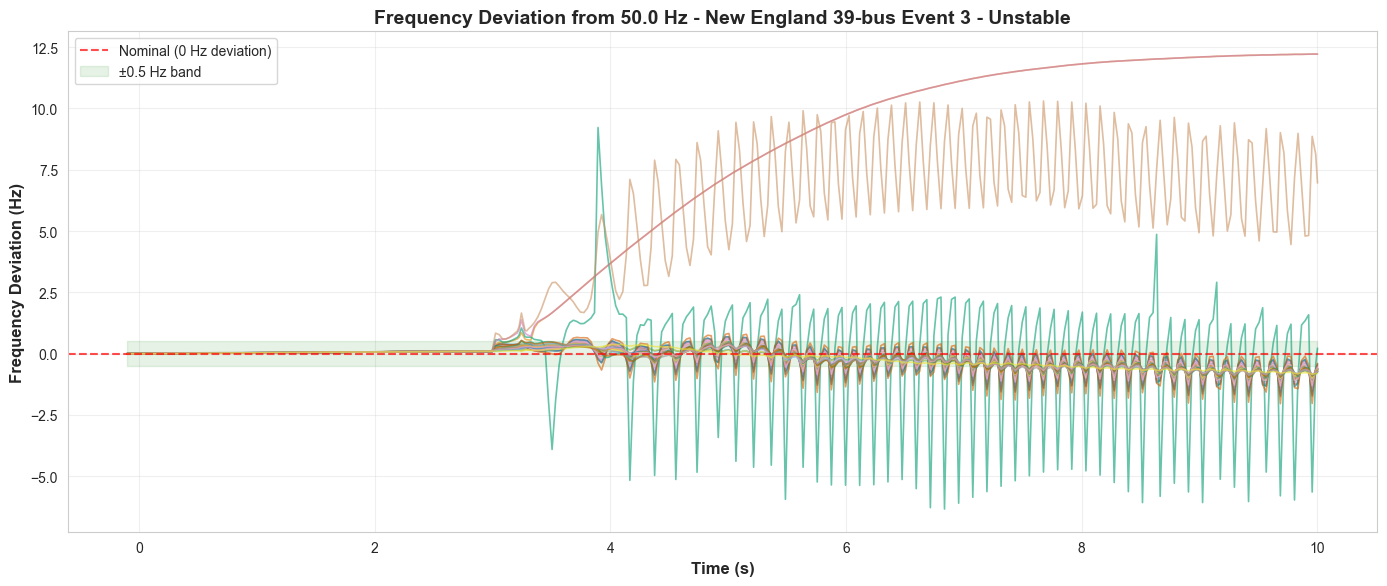

Number of buses plotted: 39
Frequency deviation range: -6.333 - 12.219 Hz


In [213]:
# Extract frequency data
freq_data = extract_bus_measurements(df_event, variable='m:fehz')

# Calculate frequency deviation from nominal
nominal_freq = 50.0  # Hz
freq_deviation = freq_data.copy()
freq_deviation.iloc[:, 1:] = freq_data.iloc[:, 1:] - nominal_freq

# Plot frequency deviation
fig, ax = plt.subplots(figsize=(14, 6))

for col in freq_deviation.columns[1:]:
    ax.plot(freq_deviation['time'], freq_deviation[col], alpha=0.6, linewidth=1.2)

ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Nominal (0 Hz deviation)')
ax.fill_between(freq_deviation['time'], -0.5, 0.5, color='green', alpha=0.1, label='±0.5 Hz band')

ax.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency Deviation (Hz)', fontsize=12, fontweight='bold')
ax.set_title(f'Frequency Deviation from {nominal_freq} Hz - {system_info[system_name]["display_name"]} Event {event_id} - {'Stable' if is_stable else 'Unstable'}', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

print(f"Number of buses plotted: {len(freq_deviation.columns) - 1}")
print(f"Frequency deviation range: {freq_deviation.iloc[:, 1:].min().min():.3f} - {freq_deviation.iloc[:, 1:].max().max():.3f} Hz")

## 5. Phase Angle Dynamics

Phase angle differences between buses indicate power flow. Large or rapidly diverging angles suggest instability.

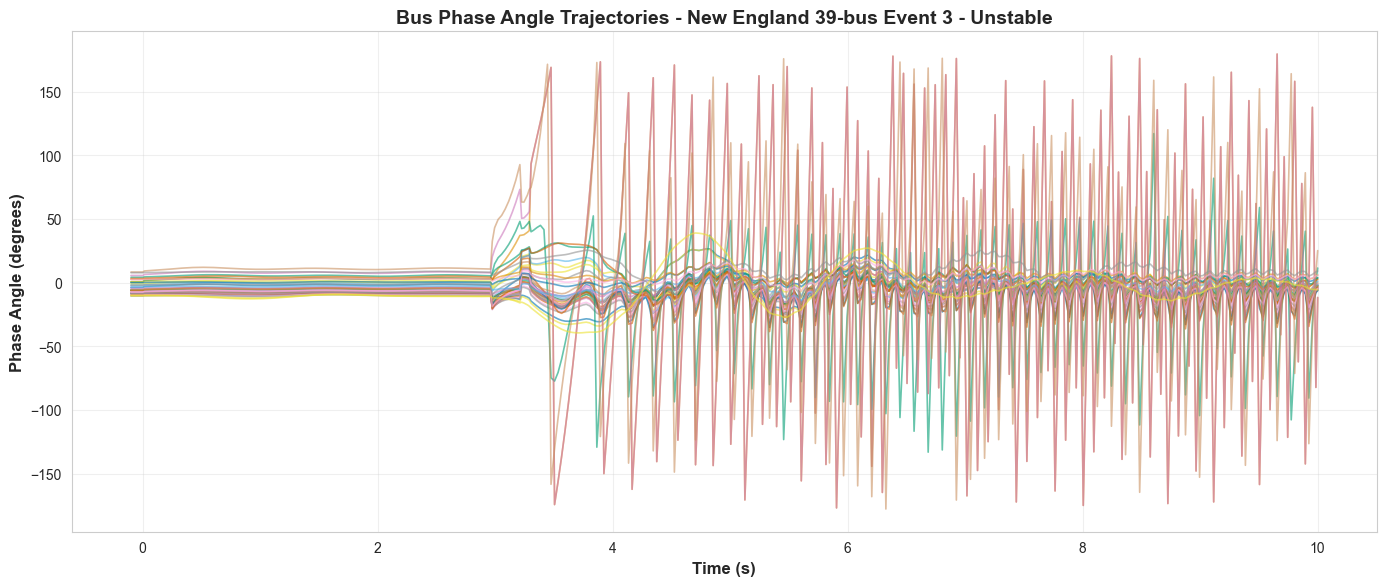

Number of buses plotted: 39
Maximum phase angle spread: 346.61 degrees
Initial phase angle spread: 18.93 degrees
Final phase angle spread: 36.80 degrees


In [214]:
# Extract phase angle data
angle_data = extract_bus_measurements(df_event, variable='m:phiu')

# Plot phase angles
fig, ax = plt.subplots(figsize=(14, 6))

for col in angle_data.columns[1:]:
    ax.plot(angle_data['time'], angle_data[col], alpha=0.6, linewidth=1.2)

ax.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
ax.set_ylabel('Phase Angle (degrees)', fontsize=12, fontweight='bold')
ax.set_title(f'Bus Phase Angle Trajectories - {system_info[system_name]["display_name"]} Event {event_id} - {'Stable' if is_stable else 'Unstable'}', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate angle spread
angle_spread = angle_data.iloc[:, 1:].max(axis=1) - angle_data.iloc[:, 1:].min(axis=1)
print(f"Number of buses plotted: {len(angle_data.columns) - 1}")
print(f"Maximum phase angle spread: {angle_spread.max():.2f} degrees")
print(f"Initial phase angle spread: {angle_spread.iloc[0]:.2f} degrees")
print(f"Final phase angle spread: {angle_spread.iloc[-1]:.2f} degrees")

## 6. Generator Rotor Speed

Generator rotor speed deviations indicate electromechanical oscillations. Persistent deviations lead to loss of synchronism.

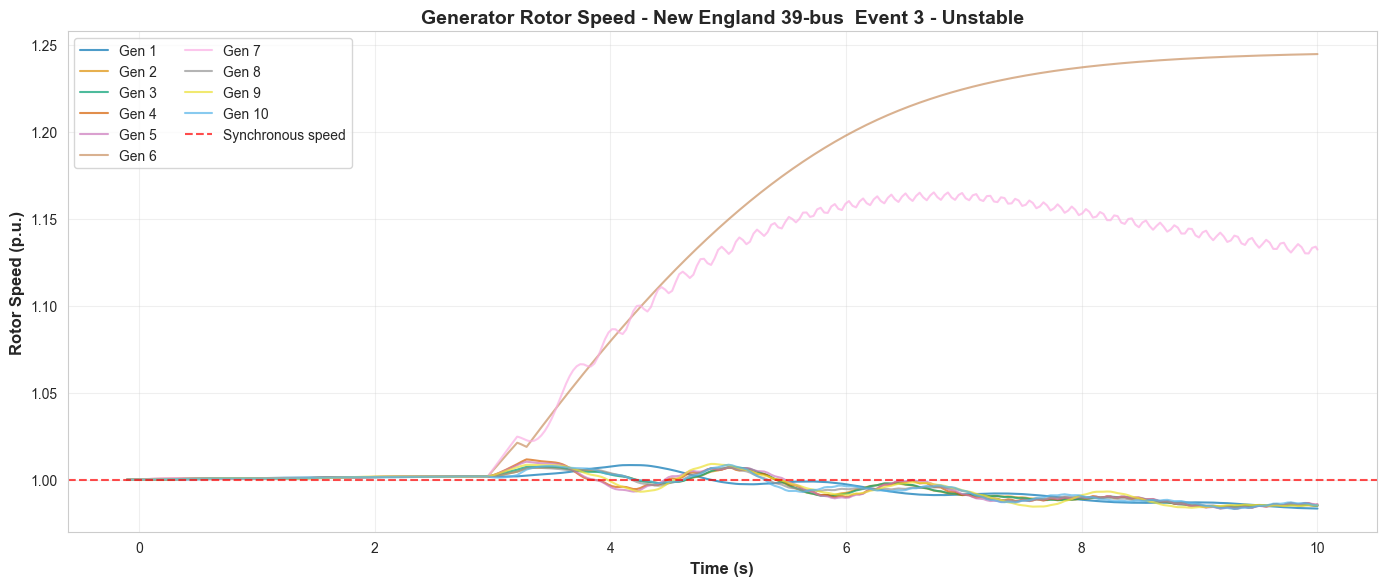

Number of generators plotted: 10
Speed range: 0.9832 - 1.2446 p.u.


In [215]:
# Extract generator speed data
speed_data = extract_generator_measurements(df_event, variable='s:xspeed')

# Plot generator speeds
fig, ax = plt.subplots(figsize=(14, 6))

for col in speed_data.columns[1:]:
    ax.plot(speed_data['time'], speed_data[col], alpha=0.7, linewidth=1.5, label=col)

ax.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Synchronous speed')

ax.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
ax.set_ylabel('Rotor Speed (p.u.)', fontsize=12, fontweight='bold')
ax.set_title(f'Generator Rotor Speed - {system_info[system_name]["display_name"]}  Event {event_id} - {'Stable' if is_stable else 'Unstable'}', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(loc='best', ncol=2)
plt.tight_layout()
plt.show()

print(f"Number of generators plotted: {len(speed_data.columns) - 1}")
print(f"Speed range: {speed_data.iloc[:, 1:].min().min():.4f} - {speed_data.iloc[:, 1:].max().max():.4f} p.u.")

## 7. Active and Reactive Power Flow

Power flow dynamics reveal how generators respond to disturbances.

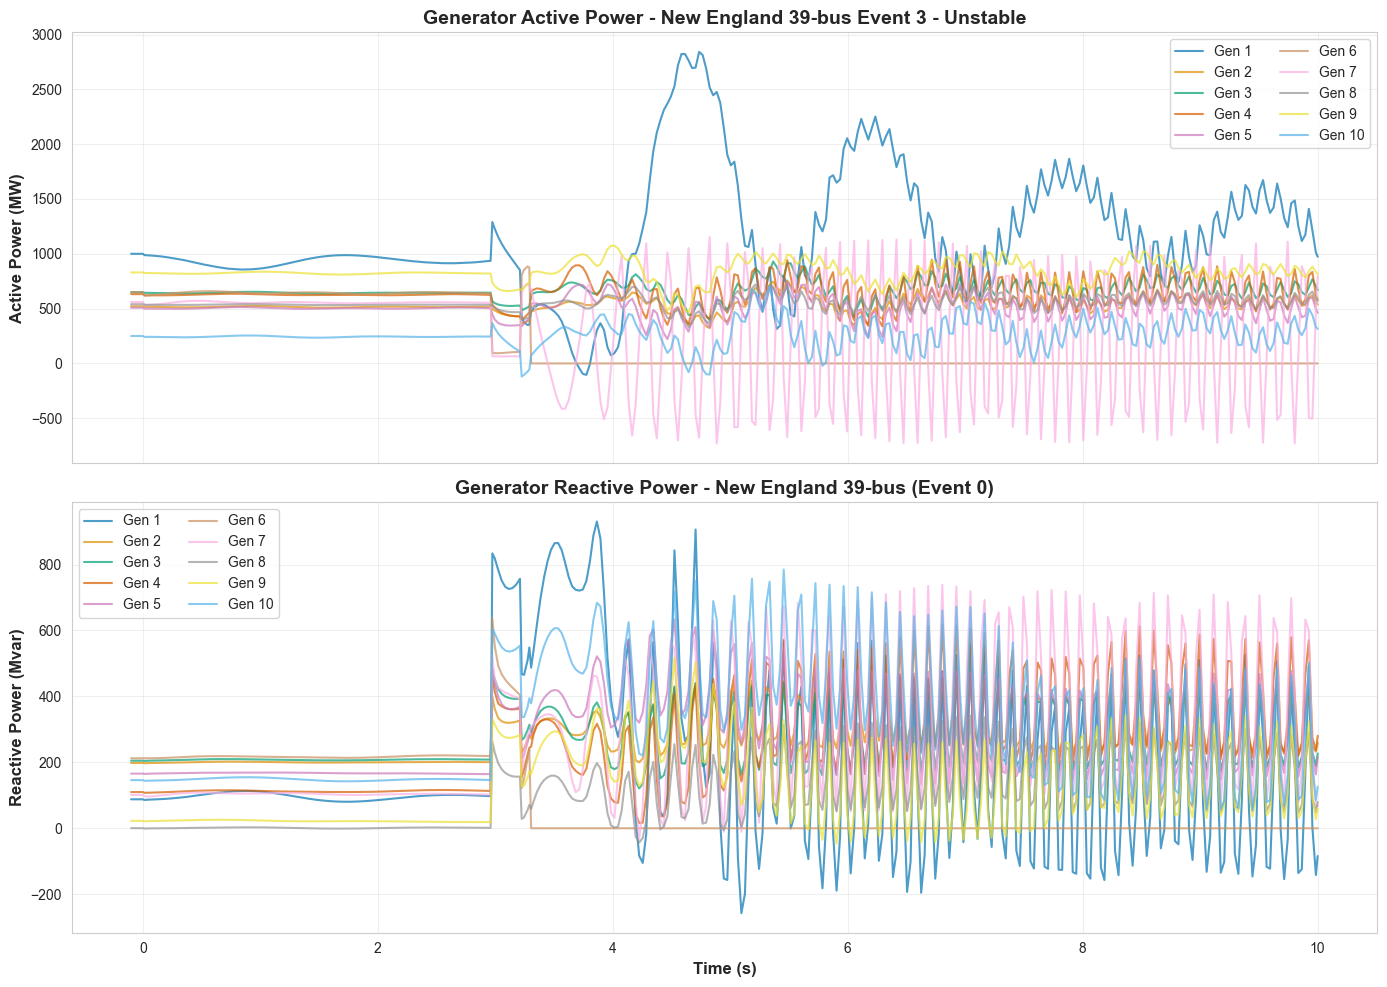

Number of generators: 10


In [216]:
# Extract power data
active_power = extract_generator_measurements(df_event, variable='s:P1')
reactive_power = extract_generator_measurements(df_event, variable='s:Q1')

# Create subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Active power
for col in active_power.columns[1:]:
    ax1.plot(active_power['time'], active_power[col], alpha=0.7, linewidth=1.5, label=col)

ax1.set_ylabel('Active Power (MW)', fontsize=12, fontweight='bold')
ax1.set_title(f'Generator Active Power - {system_info[system_name]["display_name"]} Event {event_id} - {'Stable' if is_stable else 'Unstable'}', 
              fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best', ncol=2)

# Reactive power
for col in reactive_power.columns[1:]:
    ax2.plot(reactive_power['time'], reactive_power[col], alpha=0.7, linewidth=1.5, label=col)

ax2.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Reactive Power (Mvar)', fontsize=12, fontweight='bold')
ax2.set_title(f'Generator Reactive Power - {system_info[system_name]["display_name"]} (Event 0)', 
              fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best', ncol=2)

plt.tight_layout()
plt.show()

print(f"Number of generators: {len(active_power.columns) - 1}")

## 8. Voltage Heatmap Visualization

A heatmap provides a comprehensive view of voltage evolution across all buses simultaneously.

Expected buses: 39
Actual buses in data: 39


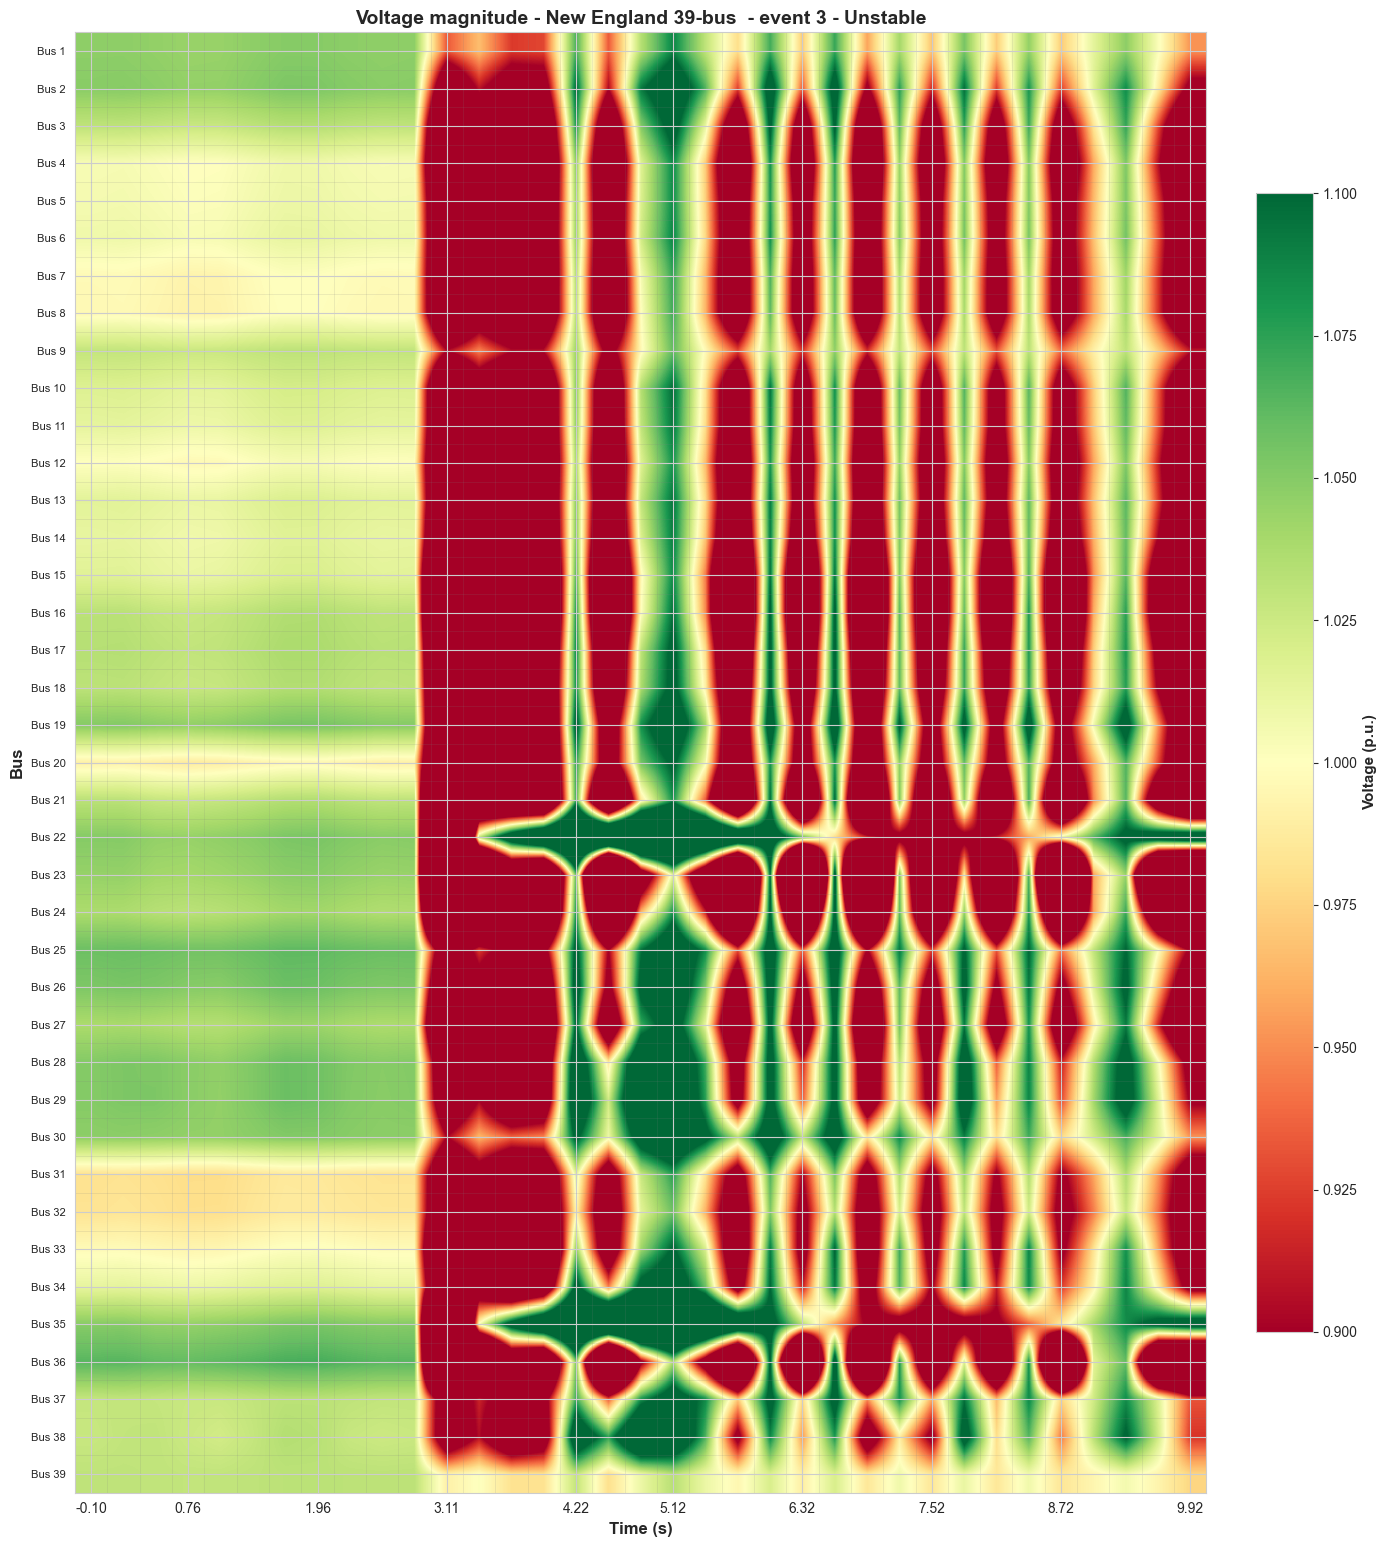


✓ Heatmap shows 39 buses from New England 39-bus


In [217]:
# Prepare voltage data for heatmap (transpose for buses on y-axis)
voltage_matrix = voltage_data.set_index('time').T

# Get number of buses for the selected system
n_buses = system_info[system_name]['n_buses']

# Verify we have the expected number of buses
actual_buses = len(voltage_matrix)
print(f"Expected buses: {n_buses}")
print(f"Actual buses in data: {actual_buses}")

if actual_buses != n_buses:
    print(f"⚠ Warning: Data contains {actual_buses} buses but {n_buses} were expected")

# Downsample time axis for better visualization
# For 9-bus: every 5th point, for 39-bus: every 10th point
downsample_rate = 5 if n_buses <= 10 else 10
voltage_matrix_ds = voltage_matrix.iloc[:, ::downsample_rate]

# Create figure with appropriate size based on number of buses
fig_height = max(6, n_buses * 0.4)  # Scale height with number of buses
fig, ax = plt.subplots(figsize=(14, fig_height))

im = ax.imshow(voltage_matrix_ds, aspect='auto', cmap='RdYlGn', 
               vmin=0.9, vmax=1.1, interpolation='bilinear')

# Customize y-axis ticks (buses)
ax.set_yticks(range(len(voltage_matrix_ds)))
ax.set_yticklabels(voltage_matrix_ds.index, fontsize=10 if n_buses <= 10 else 8)

# X-axis: time labels
n_time_ticks = min(10, len(voltage_matrix_ds.columns))
x_ticks = np.linspace(0, len(voltage_matrix_ds.columns)-1, n_time_ticks, dtype=int)
x_labels = [f"{voltage_matrix_ds.columns[i]:.2f}" for i in x_ticks]
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels, rotation=0)

ax.set_xlabel('Time (s)', fontsize=12, fontweight='bold')
ax.set_ylabel('Bus', fontsize=12, fontweight='bold')
ax.set_title(f'Voltage magnitude - {system_info[system_name]["display_name"]}  - event {event_id} - {'Stable' if is_stable else 'Unstable'}', 
             fontsize=14, fontweight='bold')

# Colorbar
cbar = plt.colorbar(im, ax=ax, label='Voltage (p.u.)', fraction=0.046, pad=0.04)
cbar.ax.set_ylabel('Voltage (p.u.)', fontsize=11, fontweight='bold')

# Add gridlines for clarity
ax.set_xticks(np.arange(len(voltage_matrix_ds.columns))-0.5, minor=True)
ax.set_yticks(np.arange(len(voltage_matrix_ds))-0.5, minor=True)
ax.grid(which='minor', color='gray', linestyle='-', linewidth=0.5, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"\n✓ Heatmap shows {actual_buses} buses from {system_info[system_name]['display_name']}")

# Calculate statistics for voltage
voltage_stats = voltage_data.iloc[:, 1:].describe().T
voltage_stats['range'] = voltage_stats['max'] - voltage_stats['min']
voltage_stats['volatility'] = voltage_data.iloc[:, 1:].std()

print("=" * 80)
print(f"VOLTAGE STATISTICS - {system_info[system_name]['display_name']} (Event 0)")
print("=" * 80)
print(voltage_stats[['mean', 'std', 'min', 'max', 'range']].round(4))
print("\n")

# Calculate statistics for frequency
freq_stats = freq_data.iloc[:, 1:].describe().T
print("=" * 80)
print(f"FREQUENCY STATISTICS - {system_info[system_name]['display_name']} (Event 0)")
print("=" * 80)
print(freq_stats[['mean', 'std', 'min', 'max']].round(4))

In [218]:
# Calculate statistics for voltage
voltage_stats = voltage_data.iloc[:, 1:].describe().T
voltage_stats['range'] = voltage_stats['max'] - voltage_stats['min']
voltage_stats['volatility'] = voltage_data.iloc[:, 1:].std()

print("=" * 80)
print(f"VOLTAGE STATISTICS - {system_name} - {'Stable' if is_stable else 'Unstable'}")
print("=" * 80)
print(voltage_stats[['mean', 'std', 'min', 'max', 'range']].round(4))
print("\n")

# Calculate statistics for frequency
freq_stats = freq_data.iloc[:, 1:].describe().T
print("=" * 80)
print(f"FREQUENCY STATISTICS - {system_name} - {'Stable' if is_stable else 'Unstable'}")
print("=" * 80)
print(freq_stats[['mean', 'std', 'min', 'max']].round(4))

VOLTAGE STATISTICS - NewEngland - Unstable
          mean     std     min     max   range
Bus 1   1.0178  0.0435  0.8944  1.0938  0.1995
Bus 2   1.0144  0.0832  0.7999  1.1603  0.3605
Bus 3   0.9709  0.1122  0.6798  1.1406  0.4609
Bus 4   0.9439  0.1117  0.6507  1.1097  0.4589
Bus 5   0.9528  0.1002  0.6937  1.1051  0.4113
Bus 6   0.9563  0.0992  0.7002  1.1077  0.4075
Bus 7   0.9464  0.0955  0.6996  1.0926  0.3930
Bus 8   0.9457  0.0934  0.7055  1.0888  0.3833
Bus 9   0.9913  0.0493  0.8600  1.0676  0.2076
Bus 10  0.9613  0.1052  0.6921  1.1175  0.4254
Bus 11  0.9583  0.1035  0.6923  1.1132  0.4209
Bus 12  0.9438  0.1079  0.6605  1.1040  0.4435
Bus 13  0.9547  0.1101  0.6710  1.1162  0.4452
Bus 14  0.9432  0.1218  0.6262  1.1172  0.4910
Bus 15  0.9167  0.1616  0.4910  1.1276  0.6366
Bus 16  0.9197  0.1777  0.4498  1.1434  0.6936
Bus 17  0.9431  0.1520  0.5443  1.1479  0.6036
Bus 18  0.9522  0.1371  0.5938  1.1442  0.5504
Bus 19  0.9820  0.1441  0.5744  1.1837  0.6093
Bus 20  0.9441  0

## 10. Comparing Stable vs Unstable Events

To demonstrate stability differences, we need to load both a stable and unstable event. This section provides a template for comparison.

In [219]:
def find_example_events(system='NewEngland', n_events=4):
    """
    Search for example stable and unstable events.
    
    Returns
    -------
    stable_id, unstable_id : int
        Event IDs for stable and unstable cases
    """
    stable_id = None
    unstable_id = None
    
    for event_id in range(n_events):
        try:
            _, is_stable = load_event_data(system=system, event_id=event_id)
            if is_stable and stable_id is None:
                stable_id = event_id
            elif not is_stable and unstable_id is None:
                unstable_id = event_id
            
            if stable_id is not None and unstable_id is not None:
                break
        except FileNotFoundError:
            continue
    
    return stable_id, unstable_id

# Find example events
stable_id, unstable_id = find_example_events(system=system_name, n_events=n_events)

if stable_id is not None and unstable_id is not None:
    print(f"Found stable event: {stable_id}")
    print(f"Found unstable event: {unstable_id}")
else:
    print("Note: Only one event available locally. To compare stable vs unstable:")
    print("1. Download additional events from the Google Drive folders")
    print("2. Place them in the appropriate dataset directory")
    stable_id = 0
    unstable_id = 0

Note: Only one event available locally. To compare stable vs unstable:
1. Download additional events from the Google Drive folders
2. Place them in the appropriate dataset directory


## 11. Switching Between Systems

To analyze a different power system, simply change the `system_name` variable in the configuration cell above and re-run all cells.

**Available systems:**
- `'NineBusSystem'` - IEEE 9-Bus System (9 buses, 3 generators)
- `'NewEngland'` - New England 39-Bus System (39 buses, 10 generators)

All visualizations will automatically adapt to the selected system's topology.

# Example: Quickly check system characteristics
print(f"Currently analyzing: {system_info[system_name]['display_name']}")
print(f"Buses: {system_info[system_name]['n_buses']}")
print(f"Generators: {system_info[system_name]['n_generators']}")
print(f"Stability: {'✓ Stable' if is_stable else '✗ Unstable'}")
print("\nTo switch systems:")
print("1. Go back to the configuration cell")
print("2. Change system_name to 'NineBusSystem' or 'NewEngland'")
print("3. Re-run all cells (Cell → Run All)")

NewEngland - Event 3
Stability: Stable
Time steps: 344


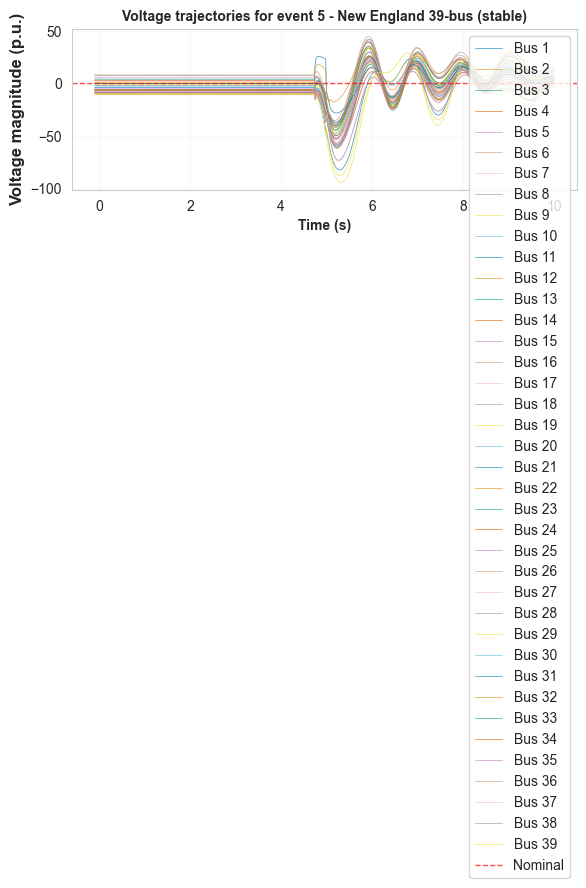

In [220]:
# Load 9-bus system data
event_id = 5
try:
    df_9bus, is_stable_9bus = load_event_data(system=system_name, event_id=event_id)
    
    print(f"{system_name} - Event 3")
    print(f"Stability: {'Stable' if is_stable_9bus else 'Unstable'}")
    print(f"Time steps: {len(df_9bus)}")
    
    # Extract voltage data
    voltage_9bus = extract_bus_measurements(df_9bus, variable='m:p')
    
    # Plot voltage trajectories
    fig, ax = plt.subplots(figsize=(6, 6))
    
    for col in voltage_9bus.columns[1:]:
        ax.plot(voltage_9bus['time'], voltage_9bus[col], alpha=0.8, linewidth=0.5, 
                markersize=1, markevery=20, label=col)
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Nominal')
    ax.set_xlabel('Time (s)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Voltage magnitude (p.u.)', fontsize=12, fontweight='bold')
    ax.set_title(f'Voltage trajectories for event {event_id} - {system_info[system_name]["display_name"]} ({'stable' if is_stable_9bus else 'Unstable'})', 
                 fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.1)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()
    
except FileNotFoundError:
    print("9-Bus system data not found locally.")
    print("Download from: https://drive.google.com/drive/folders/15wKSn-9UDSYLb_bRGtMrRNNqbQt6QRFc")

## 12. Exporting Publication-Quality Figures

Save figures in high resolution for use in papers and presentations.

✓ Saved: voltage_trajectories.png
✓ Saved: voltage_trajectories.pdf
Figure export function defined. Uncomment to save specific plots.


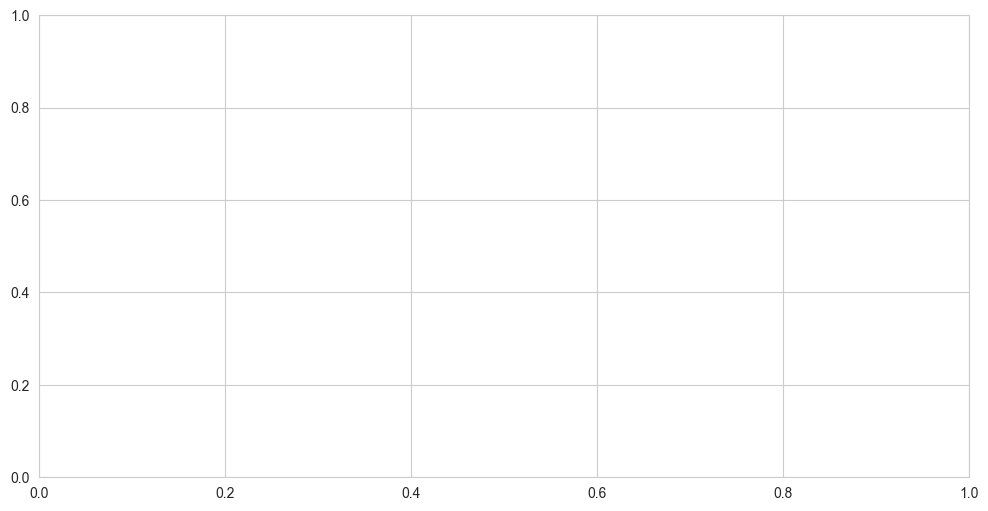

In [221]:
# Example: Save a voltage plot as PDF and PNG
def save_figure(fig, filename, dpi=300, formats=['png', 'pdf']):
    """
    Save matplotlib figure in multiple formats.
    
    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to save
    filename : str
        Base filename (without extension)
    dpi : int
        Resolution for raster formats
    formats : list
        List of file formats to save
    """
    for fmt in formats:
        save_path = f"{filename}.{fmt}"
        fig.savefig(save_path, dpi=dpi, bbox_inches='tight', format=fmt)
        print(f"✓ Saved: {save_path}")

# Example usage (uncomment to save)
fig, ax = plt.subplots(figsize=(12, 6))
# ... create your plot ...
save_figure(fig, 'voltage_trajectories', dpi=300, formats=['png', 'pdf'])

print("Figure export function defined. Uncomment to save specific plots.")

## Summary and Key Insights

This notebook demonstrated:

1. **Data Loading**: Efficient parsing of power system simulation CSV files
2. **Time-Series Visualization**: Voltage, frequency, phase angle, and power dynamics
3. **Stability Indicators**:
   - Voltage collapse or sustained oscillations
   - Frequency deviations exceeding operational limits
   - Diverging phase angles between buses
   - Generator rotor speeds departing from synchronous speed
4. **Comparative Analysis**: Stable vs unstable event characteristics
5. **Publication-Ready Plots**: Scientific styling with proper labels and units

### Next Steps

- Download the full datasets (10,000 events) from Google Drive
- Perform statistical analysis across multiple events
- Extract features for machine learning models
- Analyze critical clearing time and fault locations
- Investigate correlations between initial conditions and stability outcomes

### References

- New England System: https://drive.google.com/drive/folders/1bSb_TRky0r_lgrCHiQwAezIdAfVWLuMn
- 9-Bus System: https://drive.google.com/drive/folders/15wKSn-9UDSYLb_bRGtMrRNNqbQt6QRFc